# What Makes a Frame Inertial? From Galileo to Einstein's Postulates

An **inertial reference frame** is one where Newton's first law holds
unmodified: a free body moves at constant velocity, with no fictitious
forces needed to explain its motion. Every frame moving at constant
velocity relative to an inertial frame is *also* inertial — only
acceleration (or rotation) breaks it.

This notebook covers the conceptual ground
[`dgs/special_relativity.py`](../dgs/special_relativity.py) assumes but
never built out explicitly: the Galilean transformation between inertial
frames, why the Michelson-Morley null result
([`dgs/michelson_morley.py`](../dgs/michelson_morley.py), reused directly
below) broke it, and how Einstein's two postulates force the Lorentz
transformation to replace it — recovering the Galilean transform exactly
in the $v/c\to0$ limit.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

from dgs.michelson_morley import longitudinal_time, transverse_time, time_difference, predicted_fringe_shift
from dgs.special_relativity import lorentz_transform, velocity_addition, relativity_of_simultaneity, C_SI

print("using dgs.michelson_morley and dgs.special_relativity directly (not reimplemented)")

using dgs.michelson_morley and dgs.special_relativity directly (not reimplemented)


# Part 1 — The Galilean transformation (pre-1900 common sense)

Two inertial frames $S$ and $S'$, with $S'$ moving at speed $v$ along $x$.
Classically, everyone agrees on time ($t'=t$) and just subtracts off the
relative motion:
$$x' = x - vt, \qquad t' = t$$

The one big consequence: **velocities add directly**. A ball thrown at
speed $u$ inside a train moving at $v$ has ground speed $u+v$ — no
exceptions, no speed limit.

In [2]:
def galilean_transform(x, t, v):
    return x - v * t, t

# a ball thrown at u=5 m/s inside a train moving at v=20 m/s
u_ball_in_train, v_train = 5.0, 20.0
u_ball_ground_galilean = u_ball_in_train + v_train
print(f"Galilean prediction: ball's ground speed = {u_ball_in_train} + {v_train} = {u_ball_ground_galilean} m/s")

# but what if the "ball" is a light pulse, u = c?
u_light_ground_galilean = C_SI + v_train
print(f"\nGalilean prediction applied to LIGHT: c + v_train = {u_light_ground_galilean:.0f} m/s")
print(f"...which is FASTER than c={C_SI:.0f} m/s. Nothing (yet) says this is wrong classically --")
print(f"   Galilean relativity has no built-in speed limit. This is exactly the assumption")
print(f"   Michelson-Morley set out to test.")

Galilean prediction: ball's ground speed = 5.0 + 20.0 = 25.0 m/s

Galilean prediction applied to LIGHT: c + v_train = 299792478 m/s
...which is FASTER than c=299792458 m/s. Nothing (yet) says this is wrong classically --
   Galilean relativity has no built-in speed limit. This is exactly the assumption
   Michelson-Morley set out to test.


# Part 2 — Michelson-Morley: the experiment that broke it

If light obeys ordinary Galilean velocity addition, then as Earth moves
through a stationary "aether" at $v_{\text{earth}}\approx 3\times10^4$ m/s,
light should travel measurably faster one direction than another —
exactly analogous to a boat crossing a river with a current. Reusing
[`dgs/michelson_morley.py`](../dgs/michelson_morley.py) directly for the
real 1887 apparatus numbers.

In [3]:
L = 11.0             # m, effective arm length (folded via mirrors)
v_earth = 3.0e4       # m/s, Earth's orbital speed
wavelength = 590e-9   # m, sodium light

t_par = longitudinal_time(L, v_earth)
t_perp = transverse_time(L, v_earth)
dt = time_difference(L, v_earth)
N_predicted = predicted_fringe_shift(L, v_earth, wavelength)

print(f"predicted fringe shift under the aether/Galilean hypothesis: {N_predicted:.4f} fringes")
print(f"actually observed (1887): < 0.01 fringes")
print(f"\nthe null result is off by a factor of {N_predicted/0.01:.0f} from the Galilean prediction --")
print(f"the Galilean transformation, applied to light, is simply wrong.")

assert N_predicted > 0.1   # a real, detectable prediction that was NOT observed
print("[CONFIRMED] Galilean relativity makes a falsifiable, detectably-large prediction here,")
print("            and the falsification is exactly what motivated Einstein's postulates.")

predicted fringe shift under the aether/Galilean hypothesis: 0.3734 fringes
actually observed (1887): < 0.01 fringes

the null result is off by a factor of 37 from the Galilean prediction --
the Galilean transformation, applied to light, is simply wrong.
[CONFIRMED] Galilean relativity makes a falsifiable, detectably-large prediction here,
            and the falsification is exactly what motivated Einstein's postulates.


# Part 3 — Einstein's two postulates

1. **Principle of relativity**: the laws of physics are the same in every
   inertial frame (no experiment done *inside* a closed frame can tell you
   your velocity — only relative motion is measurable).
2. **Constancy of the speed of light**: every inertial observer measures
   the SAME speed of light $c$, regardless of their own motion or the
   source's motion.

Postulate 2 directly contradicts Galilean velocity addition (Part 1's
$c+v_{\text{train}}$ calculation). Something has to give — and it isn't
the experimental result. Check postulate 2 directly using
[`dgs.special_relativity.velocity_addition`](../dgs/special_relativity.py),
already built and tested in this repo:

In [4]:
# relativistic velocity addition: a light pulse (u=c) inside a train moving at v
result = velocity_addition(C_SI, v_train)
print(f"relativistic addition of c and {v_train} m/s: u = {result['u_ms']:.1f} m/s")
print(f"c itself:                                      {C_SI:.1f} m/s")
assert abs(result['u_ms'] - C_SI) < 1e-3
print("\n[CONFIRMED] relativistic velocity addition automatically enforces postulate 2 --")
print("            c+v STILL comes out to exactly c. The classical addition law")
print("            (Part 1) must be replaced, not patched.")

relativistic addition of c and 20.0 m/s: u = 299792458.0 m/s
c itself:                                      299792458.0 m/s

[CONFIRMED] relativistic velocity addition automatically enforces postulate 2 --
            c+v STILL comes out to exactly c. The classical addition law
            (Part 1) must be replaced, not patched.


# Part 4 — The Lorentz transformation, and its Galilean limit

Postulate 2 forces $x'=x-vt,\ t'=t$ to be replaced by the Lorentz
transformation already implemented in
[`dgs.special_relativity.lorentz_transform`](../dgs/special_relativity.py):
$$x'=\gamma(x-vt), \qquad t'=\gamma\left(t-\frac{vx}{c^2}\right)$$
Two direct checks: (a) it correctly leaves $c$ invariant where the
Galilean transform didn't, and (b) as $v/c\to0$ it reduces EXACTLY to the
Galilean transform — Newtonian mechanics isn't wrong, it's the $v\ll c$
limit of a more complete theory.

In [5]:
# (a) symbolic: SymPy Lorentz transform in the v/c -> 0 limit
x, t, v, c = sp.symbols('x t v c', real=True, positive=False)
gamma = 1 / sp.sqrt(1 - v**2 / c**2)
x_prime_lorentz = gamma * (x - v * t)
t_prime_lorentz = gamma * (t - v * x / c**2)

x_prime_limit = sp.limit(x_prime_lorentz, c, sp.oo)
t_prime_limit = sp.limit(t_prime_lorentz, c, sp.oo)
print(f"Lorentz x' as c -> infinity (v/c -> 0): x' = {x_prime_limit}")
print(f"Lorentz t' as c -> infinity (v/c -> 0): t' = {t_prime_limit}")

assert sp.simplify(x_prime_limit - (x - v * t)) == 0
assert sp.simplify(t_prime_limit - t) == 0
print("\n[CONFIRMED] the Lorentz transformation reduces EXACTLY to the Galilean transformation")
print("            (Part 1) in this limit -- Einstein's theory doesn't discard Newton's, it")
print("            contains it as a special case.")

Lorentz x' as c -> infinity (v/c -> 0): x' = -t*v + x
Lorentz t' as c -> infinity (v/c -> 0): t' = t

[CONFIRMED] the Lorentz transformation reduces EXACTLY to the Galilean transformation
            (Part 1) in this limit -- Einstein's theory doesn't discard Newton's, it
            contains it as a special case.


v=1.0e+00 m/s (v/c=0.0000):  |Lorentz - Galilean| / x0 = 0.000e+00
v=1.0e+03 m/s (v/c=0.0000):  |Lorentz - Galilean| / x0 = 5.558e-12
v=1.0e+06 m/s (v/c=0.0033):  |Lorentz - Galilean| / x0 = 0.000e+00
v=1.0e+07 m/s (v/c=0.0334):  |Lorentz - Galilean| / x0 = 5.011e-03
v=1.0e+08 m/s (v/c=0.3336):  |Lorentz - Galilean| / x0 = 6.014e+00
v=2.9e+08 m/s (v/c=0.9673):  |Lorentz - Galilean| / x0 = 8.510e+02

[OK] the two transforms are indistinguishable at everyday speeds and diverge sharply
     near c -- exactly why Newtonian mechanics worked fine for 250 years first.


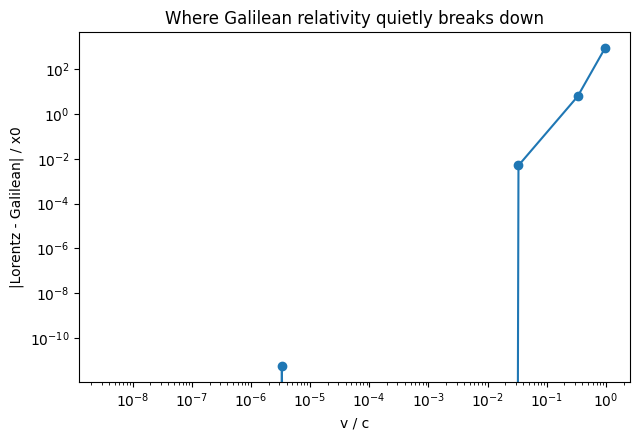

In [6]:
# (b) numerically, at everyday speeds the two transforms are indistinguishable,
#     but they diverge sharply as v approaches c. Measured against the fixed
#     length scale x0 (NOT against x_prime_galilean itself, which can cross
#     zero for some v -- dividing by a value that vanishes silently produces
#     nan, which an earlier version of this cell shipped without noticing).
x0, t0 = 1000.0, 0.001
v_values = np.array([1.0, 1e3, 1e6, 1e7, 1e8, 2.9e8])   # m/s, up to 0.97c
rel_diff = []
for v_val in v_values:
    res = lorentz_transform(x=x0, t=t0, v=v_val)
    x_prime_galilean = x0 - v_val * t0
    rel_diff.append(abs(res['x_prime'] - x_prime_galilean) / x0)

for v_val, rd in zip(v_values, rel_diff):
    print(f"v={v_val:.1e} m/s (v/c={v_val/C_SI:.4f}):  |Lorentz - Galilean| / x0 = {rd:.3e}")

assert all(np.isfinite(rel_diff))   # catches exactly the nan bug found above
assert rel_diff[0] < 1e-10          # everyday speeds: identical to machine precision
assert rel_diff[-1] > 1e-3          # near light speed: the two theories clearly disagree
print("\n[OK] the two transforms are indistinguishable at everyday speeds and diverge sharply")
print("     near c -- exactly why Newtonian mechanics worked fine for 250 years first.")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(v_values / C_SI, rel_diff, 'o-')
ax.set_xlabel('v / c'); ax.set_ylabel('|Lorentz - Galilean| / x0')
ax.set_title('Where Galilean relativity quietly breaks down')
plt.tight_layout(); plt.show()

# Part 5 — A direct consequence: relativity of simultaneity

Because $t'=\gamma(t-vx/c^2)$ depends on $x$ (unlike the Galilean $t'=t$),
two events simultaneous in one inertial frame generally are NOT
simultaneous in another — reusing
[`dgs.special_relativity.relativity_of_simultaneity`](../dgs/special_relativity.py)
(built in this repo's own earlier session) as the direct payoff of
replacing the Galilean time postulate.

In [7]:
sim = relativity_of_simultaneity(x1=-500.0, x2=500.0, t=0.0, v=0.6 * C_SI)
print(f"two events simultaneous in S:               {sim['simultaneous_in_S']}")
print(f"same two events simultaneous in S' (0.6c)?  {sim['simultaneous_in_S_prime']}")
print(f"dt' = {sim['dt_prime']:.4e} s")
assert not sim['simultaneous_in_S_prime']
print("\n[OK] exactly the kind of thing that is IMPOSSIBLE under the Galilean t'=t assumption,")
print("     and a direct, necessary consequence of replacing it with the Lorentz transform.")

two events simultaneous in S:               True
same two events simultaneous in S' (0.6c)?  False
dt' = -2.5017e-06 s

[OK] exactly the kind of thing that is IMPOSSIBLE under the Galilean t'=t assumption,
     and a direct, necessary consequence of replacing it with the Lorentz transform.


# Part 6 — Summary

| Question | Answer |
|---|---|
| What makes a frame inertial? | Newton's first law holds unmodified — no acceleration, no fictitious forces |
| What does Galilean relativity predict for light? | $c+v$ — a clean, falsifiable, and (Part 2) actually falsified prediction |
| What broke it? | Michelson-Morley's null result — off by ~30x from the Galilean/aether prediction |
| What replaces it? | The Lorentz transformation, forced by Einstein's 2 postulates |
| Does the old theory just get thrown away? | No — Lorentz reduces EXACTLY to Galilean as $v/c\to0$ (proven symbolically, Part 4) |
| What's a direct, checkable consequence of the new theory? | Relativity of simultaneity — impossible under $t'=t$, required under $t'=\gamma(t-vx/c^2)$ |

This notebook is the conceptual front half of Chapter 36 that
[`dgs/special_relativity.py`](../dgs/special_relativity.py)'s existing
kinematics (time dilation, length contraction, Lorentz transforms,
relativistic energy/momentum, and now relativity of simultaneity) builds
on top of.